# 01 - Exploratory data analysis

IBM Telco Customer Churn: 7,043 customers, 21 columns, target `Churn`.
Goal: understand data quality, class balance and which attributes relate to churn, to guide feature
engineering (`02`) and modelling (`03`). Everything here uses the cleaned data produced by
`src/data/preprocess.py` (same data that is stored in PostgreSQL).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent          # notebooks/ lives one level below the project root
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4), "axes.titlesize": 11})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

In [2]:
from src.data.load import load_raw
from src.data.preprocess import clean
from src.features.build_features import CATEGORICAL, BOOLEAN, NUMERIC

raw = load_raw()
df = clean(raw)
print("raw:", raw.shape, "| cleaned:", df.shape)
raw.head(3).T

raw: (7043, 21) | cleaned: (7043, 21)


,0,1,2
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,No phone service,No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes


## 1. Data quality

In [3]:
print("duplicated customerID  :", int(raw["customerID"].duplicated().sum()))
print("NaN cells in raw file    :", int(raw.isna().sum().sum()))
blank = raw["TotalCharges"].str.strip().eq("")
print("blank TotalCharges (raw) :", int(blank.sum()), "| all have tenure == 0:", bool((raw.loc[blank, "tenure"] == 0).all()))
print()
print("cleaned dtypes:", df.dtypes.astype(str).value_counts().to_dict())
df.describe().round(2)

duplicated customerID  : 0
NaN cells in raw file    : 0
blank TotalCharges (raw) : 11 | all have tenure == 0: True

cleaned dtypes: {'str': 12, 'bool': 6, 'int64': 1, 'float64': 1, 'Float64': 1}


,tenure,monthly_charges,total_charges
count,7043.00,7043.00,7043.0
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.0
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.6
max,72.00,118.75,8684.8


## 2. Target balance

churn rate: 26.5%  (1869 churned / 7043 customers)  ->  imbalance ratio 2.77 : 1


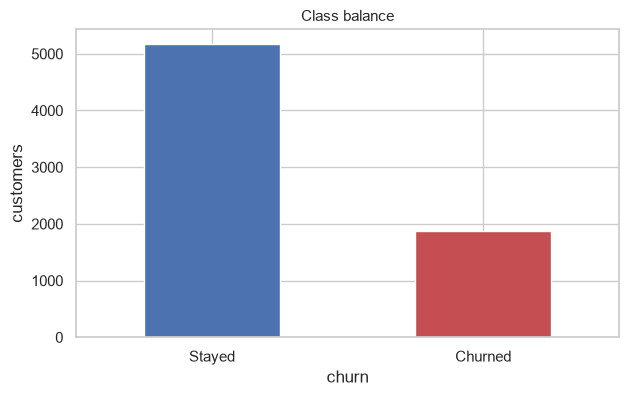

In [4]:
rate = df["churn"].mean()
print(f"churn rate: {rate:.1%}  ({int(df['churn'].sum())} churned / {len(df)} customers)  ->  imbalance ratio {(1-rate)/rate:.2f} : 1")
ax = df["churn"].map({False: "Stayed", True: "Churned"}).value_counts().plot.bar(color=["#4c72b0", "#c44e52"], rot=0)
ax.set_ylabel("customers"); ax.set_title("Class balance"); plt.show()

## 3. Numeric features vs churn

      tenure        monthly_charges        total_charges        
        mean median            mean median          mean  median
churn                                                           
False   37.6   38.0            61.3   64.4        2549.9  1679.5
True    18.0   10.0            74.4   79.6        1531.8   703.6


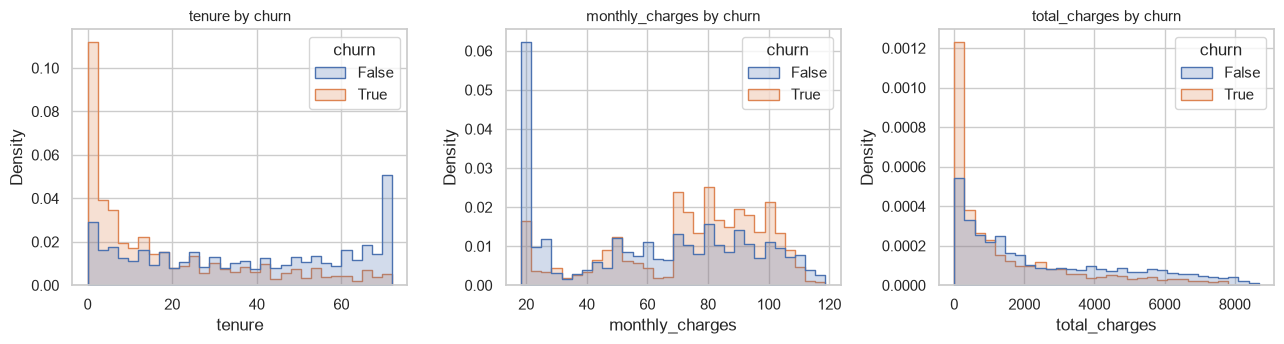

In [5]:
num = NUMERIC
print(df.groupby("churn")[num].agg(["mean", "median"]).round(1))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, num):
    sns.histplot(data=df, x=c, hue="churn", stat="density", common_norm=False, element="step", bins=30, ax=ax)
    ax.set_title(f"{c} by churn")
plt.tight_layout(); plt.show()

Churn rate by tenure (months)
           mean  size
tenure               
(-1, 6]   0.529  1481
(6, 12]   0.359   705
(12, 24]  0.287  1024
(24, 36]  0.216   832
(36, 48]  0.190   762
(48, 60]  0.144   832
(60, 72]  0.066  1407

Churn rate by monthly charges
                  mean  size
monthly_charges             
(0, 30]          0.098  1653
(30, 50]         0.308   646
(50, 70]         0.208  1161
(70, 90]         0.378  1844
(90, 120]        0.328  1739



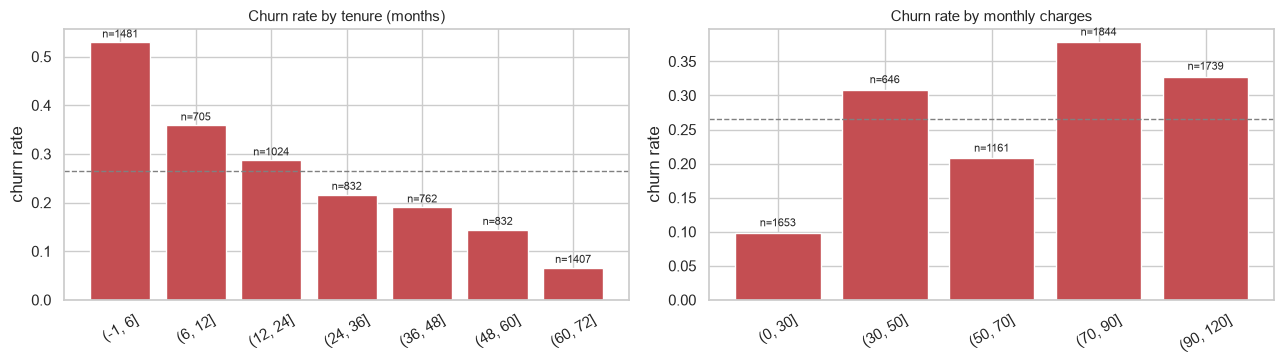

In [6]:
def rate_by(bins_col, ax, title):
    g = df.groupby(bins_col, observed=True)["churn"].agg(["mean", "size"])
    print(title); print(g.round(3).to_string()); print()
    bars = ax.bar(g.index.astype(str), g["mean"], color="#c44e52")
    ax.axhline(df["churn"].mean(), color="grey", ls="--", lw=1)
    for b, n in zip(bars, g["size"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"n={n}", ha="center", fontsize=8)
    ax.set_title(title); ax.set_ylabel("churn rate"); ax.tick_params(axis="x", rotation=30)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
rate_by(pd.cut(df["tenure"], [-1, 6, 12, 24, 36, 48, 60, 72]), axes[0], "Churn rate by tenure (months)")
rate_by(pd.cut(df["monthly_charges"], [0, 30, 50, 70, 90, 120]), axes[1], "Churn rate by monthly charges")
plt.tight_layout(); plt.show()

## 4. Categorical features vs churn

In [7]:
cats = CATEGORICAL + BOOLEAN
rows = []
for c in cats:
    for level, g in df.groupby(c)["churn"]:
        rows.append((c, str(level), g.mean(), len(g)))
table = pd.DataFrame(rows, columns=["feature", "level", "churn_rate", "n"])
print("Highest and lowest churn rates (levels with n >= 200):")
big = table[table.n >= 200].sort_values("churn_rate")
print(pd.concat([big.head(6), big.tail(6)]).round(3).to_string(index=False))

Highest and lowest churn rates (levels with n >= 200):
          feature               level  churn_rate    n
         contract            Two year       0.028 1695
 internet_service                  No       0.074 1526
    online_backup No internet service       0.074 1526
device_protection No internet service       0.074 1526
     streaming_tv No internet service       0.074 1526
 streaming_movies No internet service       0.074 1526
     tech_support                  No       0.416 3473
   senior_citizen                True       0.417 1142
  online_security                  No       0.418 3498
 internet_service         Fiber optic       0.419 3096
         contract      Month-to-month       0.427 3875
   payment_method    Electronic check       0.453 2365


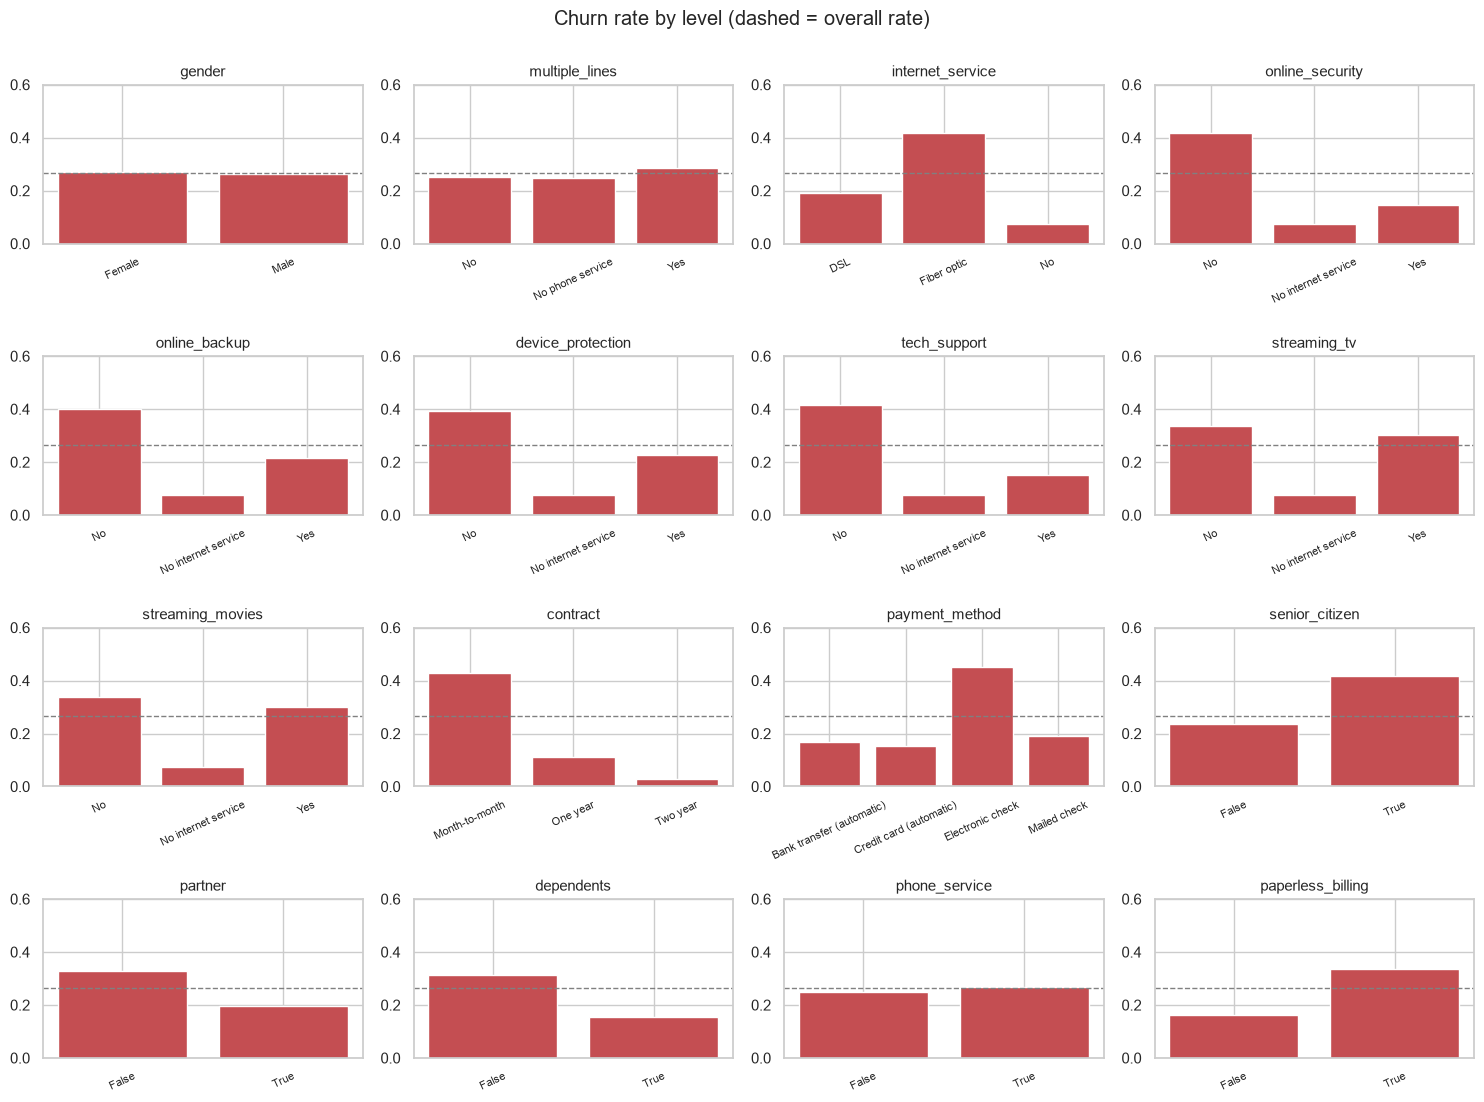

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, c in zip(axes.ravel(), cats):
    g = df.groupby(c)["churn"].mean()
    ax.bar(g.index.astype(str), g.values, color="#c44e52")
    ax.axhline(df["churn"].mean(), color="grey", ls="--", lw=1)
    ax.set_title(c); ax.set_ylim(0, 0.6); ax.tick_params(axis="x", rotation=25, labelsize=8)
plt.suptitle("Churn rate by level (dashed = overall rate)", y=1.0)
plt.tight_layout(); plt.show()

## 5. Strength of association with churn

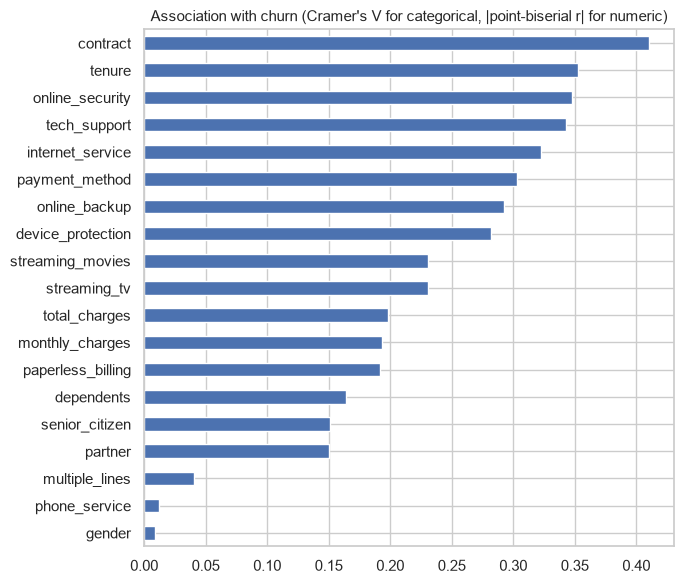

strongest:
contract             0.410
tenure               0.352
online_security      0.347
tech_support         0.343
internet_service     0.322
payment_method       0.303
online_backup        0.292
device_protection    0.282
weakest:
gender            0.009
phone_service     0.012
multiple_lines    0.040
partner           0.150
senior_citizen    0.151
dependents        0.164


In [9]:
from scipy.stats import chi2_contingency, pointbiserialr

def cramers_v(x, y):
    t = pd.crosstab(x, y)
    chi2 = chi2_contingency(t, correction=False)[0]
    return float(np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))))

assoc = {c: cramers_v(df[c], df["churn"]) for c in cats}
assoc.update({c: abs(pointbiserialr(df["churn"].astype(int), df[c])[0]) for c in NUMERIC})
assoc = pd.Series(assoc).sort_values()
assoc.plot.barh(figsize=(7, 6), color="#4c72b0")
plt.title("Association with churn (Cramer's V for categorical, |point-biserial r| for numeric)")
plt.tight_layout(); plt.show()
print("strongest:"); print(assoc.sort_values(ascending=False).round(3).head(8).to_string())
print("weakest:"); print(assoc.sort_values().round(3).head(6).to_string())

## 6. Relationships between features

corr(total_charges, tenure * monthly_charges): 1.0
relative gap (total - tenure*monthly) / (tenure*monthly):
count    7032.0
mean        0.0
std       0.051
min      -0.311
25%       -0.02
50%         0.0
75%        0.02
max       0.573

corr(tenure, total_charges): 0.826 | corr(monthly, total_charges): 0.651


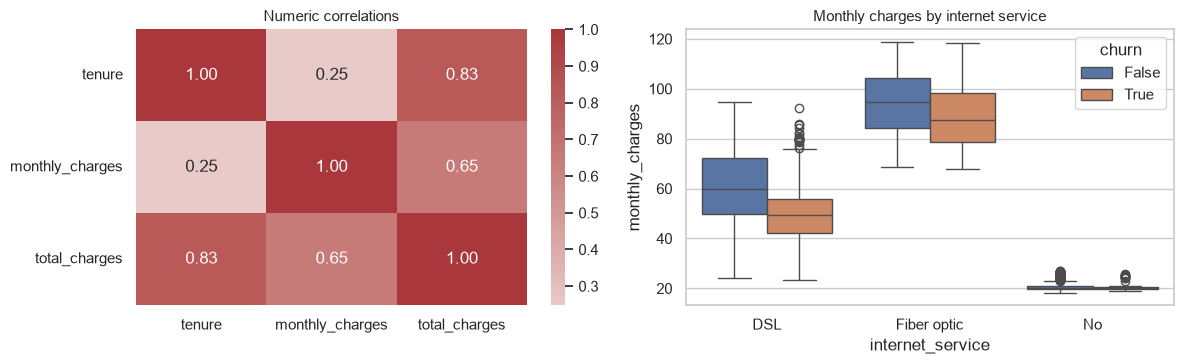

In [10]:
approx = df["tenure"] * df["monthly_charges"]
print("corr(total_charges, tenure * monthly_charges):", round(np.corrcoef(df["total_charges"], approx)[0, 1], 3))
rel = ((df["total_charges"] - approx) / approx.replace(0, np.nan)).dropna()
print("relative gap (total - tenure*monthly) / (tenure*monthly):")
print(rel.describe().round(3).to_string())
print()
print("corr(tenure, total_charges):", round(df["tenure"].corr(df["total_charges"]), 3),
      "| corr(monthly, total_charges):", round(df["monthly_charges"].corr(df["total_charges"]), 3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(df[NUMERIC].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0]); axes[0].set_title("Numeric correlations")
sns.boxplot(data=df, x="internet_service", y="monthly_charges", hue="churn", ax=axes[1]); axes[1].set_title("Monthly charges by internet service")
plt.tight_layout(); plt.show()

customers per cell:
tenure_bin      (-1, 12]  (12, 24]  (24, 48]  (48, 72]
contract                                              
Month-to-month      1994       737       802       342
One year             124       197       518       634
Two year              68        90       274      1263
churn rate per cell:
tenure_bin      (-1, 12]  (12, 24]  (24, 48]  (48, 72]
contract                                              
Month-to-month     0.514     0.377     0.329     0.260
One year           0.105     0.081     0.106     0.129
Two year           0.000     0.000     0.022     0.033


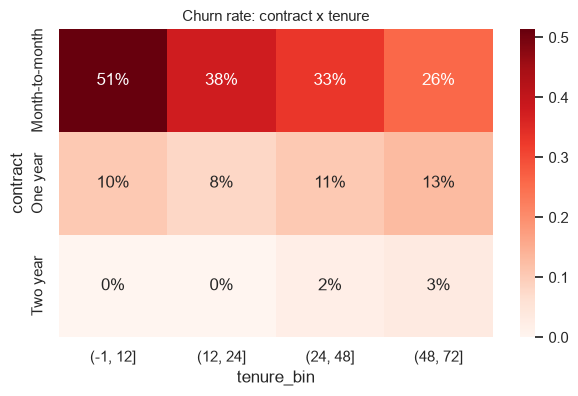

In [11]:
pivot = (df.assign(tenure_bin=pd.cut(df["tenure"], [-1, 12, 24, 48, 72]))
           .pivot_table(index="contract", columns="tenure_bin", values="churn", aggfunc="mean", observed=True))
counts = (df.assign(tenure_bin=pd.cut(df["tenure"], [-1, 12, 24, 48, 72]))
            .pivot_table(index="contract", columns="tenure_bin", values="churn", aggfunc="size", observed=True))
print("customers per cell:"); print(counts.to_string())
print("churn rate per cell:"); print(pivot.round(3).to_string())
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds"); plt.title("Churn rate: contract x tenure"); plt.show()

## 7. Add-on services

In [12]:
addons = ["online_security", "online_backup", "device_protection", "tech_support", "streaming_tv", "streaming_movies"]
inet = df[df["internet_service"] != "No"].copy()
inet["n_addons"] = (inet[addons] == "Yes").sum(axis=1)
g = inet.groupby("n_addons")["churn"].agg(["mean", "size"]).round(3)
print("Internet customers only, churn rate by number of add-ons:"); print(g.to_string())
print()
for c in addons:
    print(f"{c:20s}", inet.groupby(c)["churn"].mean().round(3).to_dict())

Internet customers only, churn rate by number of add-ons:
           mean  size
n_addons             
0         0.522   693
1         0.458   966
2         0.358  1033
3         0.274  1118
4         0.223   852
5         0.124   571
6         0.053   284

online_security      {'No': 0.418, 'Yes': 0.146}
online_backup        {'No': 0.399, 'Yes': 0.215}
device_protection    {'No': 0.391, 'Yes': 0.225}
tech_support         {'No': 0.416, 'Yes': 0.152}
streaming_tv         {'No': 0.335, 'Yes': 0.301}
streaming_movies     {'No': 0.337, 'Yes': 0.299}


## Findings

- **Data quality:** no duplicates or NaNs. The 11 blank `TotalCharges` are all tenure-0 customers (nothing billed yet), set to 0.
- **Imbalance:** 26.5% churn (2.77 : 1). Judge models by PR-AUC / recall, not accuracy.
- **Contract is the strongest signal** (Cramer's V 0.41): churn is 42.7% month-to-month vs 2.8% on two-year contracts. Month-to-month customers in their first year churn at 51%, while 1- and 2-year contracts stay at or below 13% at every tenure.
- **Tenure:** churn falls from 53% (<= 6 months) to 6.6% (> 60 months). Churners' median tenure is 10 months vs 38 for stayers.
- **Services and billing:** fibre-optic customers churn at 41.9% (customers without internet: 7.4%); electronic-check payers at 45.3%. Customers without online security or tech support churn at about 42% vs about 15% with them. Among internet customers, churn drops steadily with the number of add-ons (52% with none, 5% with all six), but the streaming add-ons barely matter (30-34% either way). This is association, not causation: customers who buy add-ons are probably already more committed.
- **Price is not monotonic:** lowest churn at <= $30/month (9.8%), then 30.8% / 20.8% / 37.8% / 32.8% across the higher bands. Price effects are mixed with the type of service.
- **Weak or no signal:** `gender` (V = 0.009), `phone_service` (0.012) and `multiple_lines` (0.040).
- **Redundancy:** `total_charges` is almost `tenure x monthly_charges` (correlation ~1.0, median gap 0, std 5%). The remaining gap reflects price changes over a customer's life, so it is a candidate engineered feature (tested in `02`).

## Implications

1. Tree models should capture the contract x tenure interaction without help; a linear baseline needs it explicitly.
2. Test engineered features that summarise add-ons, billing and the `total_charges` gap (`02`).
3. Keep all 19 raw features for now; the weak ones are cheap and the form needs them (to be checked in `04`).